In [5]:
#探讨图像
import dnnlpy
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

dnnlpy.set_matplotlib_format('highdpi')
print('PyTorch version:', torch.__version__)

PyTorch version: 2.12.0.dev20260408+cu128


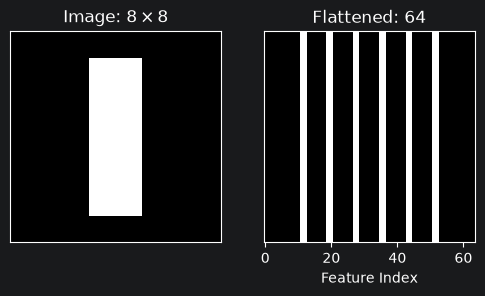

In [6]:
image = torch.zeros(8, 8) #创建一个8x8的全黑（全0）矩阵
image[1:7, 3:5] = 1.0 #将第1至6行，第3至4列变白（像素值1）

flattened = image.view(1, -1)
flattened = flattened.repeat(image.numel(), 1)

fig = plt.figure(1, figsize=(6, 3))
ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(image, cmap='gray', vmin=0, vmax=1)
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_title(r'Image: $8 \times 8$')
ax2 = fig.add_subplot(1, 2, 2)
ax2.imshow(flattened, cmap='gray', vmin=0, vmax=1)
ax2.set_aspect('equal')
ax2.set_yticks([])
ax2.set_xlabel('Feature Index')
ax2.set_title('Flattened: 64')
plt.show()

In [7]:
#mlp的权重参数数量
mlp1 = nn.Linear(28 * 28, 512, bias=False)
mlp2 = nn.Linear(3 * 224 * 224, 512, bias=False)
params1 = dnnlpy.count_params(mlp1)
params2 = dnnlpy.count_params(mlp2)

print(f'MNIST input layer: {params1:,} parameters.')
print(f'ImageNet input layer: {params2:,} parameters.')

MNIST input layer: 401,408 parameters.
ImageNet input layer: 77,070,336 parameters.


In [8]:
#mlp的全连接和cnn局部连接的输入特征数量区别
image_size = 8
kernel_size = 3

full_connections = image_size * image_size
local_connections = kernel_size * kernel_size

print('Connections used by one fully connected unit:', full_connections)
print('Connections used by one local 3x3 unit:', local_connections)

Connections used by one fully connected unit: 64
Connections used by one local 3x3 unit: 9


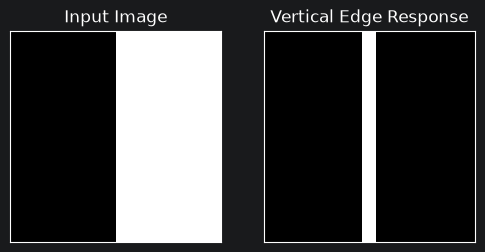

In [9]:
#使用一个检测图像竖直边缘的卷积核kernel做计算，得出该图像竖直边缘的特征图response
image = torch.zeros(1, 1, 32, 32)
image[..., 16:] = 1.0 #..., 16:表示前面维度不变，最后一个维度列从索引16开始一直到最后值设为1，得到图像左半部分为0，右半部分为1，形成一条竖直边界

kernel=torch.tensor(
    [
        [-1.0,0.0,1.0],
        [-1.0,0.0,1.0],
        [-1.0,0.0,1.0],
    ]
).view(1,1,3,3)

response=F.conv2d(image,kernel) #执行二维卷积运算.image：输入图像;kernel：卷积核权重

fig = plt.figure(2, figsize=(6, 3))
ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(image[0, 0], cmap='gray')
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_title('Input Image')
ax2 = fig.add_subplot(1, 2, 2)
ax2.imshow(response[0, 0], cmap='gray')
ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_title('Vertical Edge Response')
plt.show()

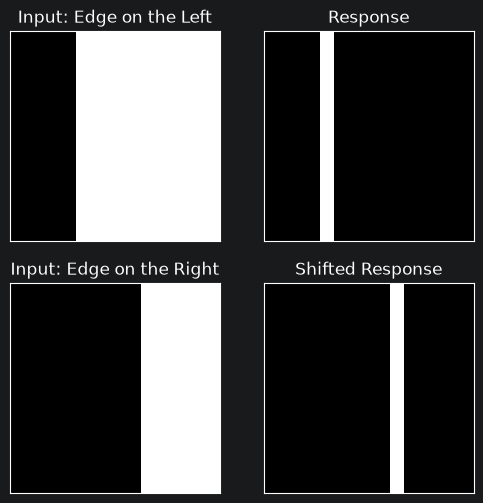

In [10]:
#图像发生平移后，经过卷积计算得到的响应response也会平移
image_left = torch.zeros(1, 1, 32, 32)
image_left[..., 10:] = 1.0

image_right = torch.zeros(1, 1, 32, 32)
image_right[..., 20:] = 1.0

response_left = F.conv2d(image_left, kernel)
response_right = F.conv2d(image_right, kernel)

fig = plt.figure(3, figsize=(6, 6))
ax1 = fig.add_subplot(2, 2, 1)
ax1.imshow(image_left[0, 0], cmap='gray')
ax1.set_title('Input: Edge on the Left')
ax2 = fig.add_subplot(2, 2, 2)
ax2.imshow(response_left[0, 0], cmap='gray')
ax2.set_title('Response')
ax3 = fig.add_subplot(2, 2, 3)
ax3.imshow(image_right[0, 0], cmap='gray')
ax3.set_title('Input: Edge on the Right')
ax4 = fig.add_subplot(2, 2, 4)
ax4.imshow(response_right[0, 0], cmap='gray')
ax4.set_title('Shifted Response')

for ax in [ax1, ax2, ax3, ax4]:
    ax.set_xticks([])
    ax.set_yticks([])

plt.show()